Task 1

Data retrieved from frost.met.no!


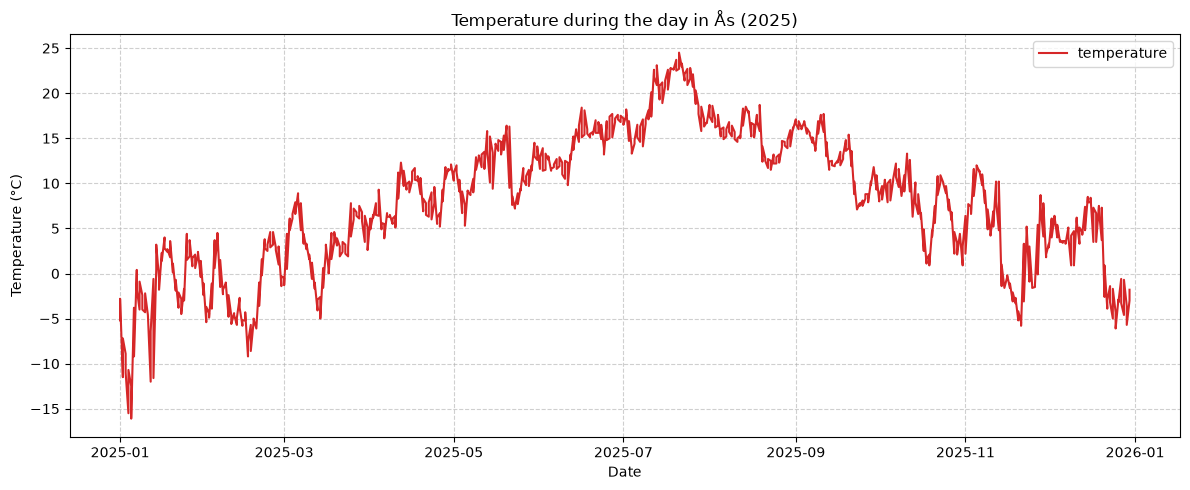

Summary table for 2025
 Metrikk  Temperature (°C)
    Mean          7.903571
  Median          8.350000
 Minimum        -16.100000
Maksimum         24.500000


In [13]:
import requests
import pandas as pd
import matplotlib.pyplot as plt 
import frost_met_code as fmc

# Insert your own client ID here
client_id = fmc.client_credentials


# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()



# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])



# This will return a Dataframe with all of the observations in a table format
rows = []

for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)

df = pd.concat(rows, ignore_index=True)

df.head()

df["referenceTime"] = pd.to_datetime(df["referenceTime"])

plt.figure(figsize=(12, 5))
plt.plot(df["referenceTime"], df["value"], color="tab:red", label="temperature")
plt.title("Temperature during the day in Ås (2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

summary_df = pd.DataFrame({
    "Metrikk": ["Mean", "Median", "Minimum", "Maksimum"],
    "Temperature (°C)": [
        df["value"].mean(),
        df["value"].median(),
        df["value"].min(),
        df["value"].max()
    ]
})

print("Summary table for 2025")
print(summary_df.to_string(index=False))